# 06 · ModernBERT-large with LoRA: the tagging method `modernbert_lora`

This notebook presents the tagging method `modernbert_lora`: a pretrained encoder,
[ModernBERT-large](https://huggingface.co/answerdotai/ModernBERT-large)
(395M parameters, 8,192-token context, pretrained on text and code), fine-tuned to predict the 8
focus tags from a problem's statement and solution. Only low-rank updates (LoRA) and the
classification head are trained: 1% to 4% of the weights, depending on the LoRA rank, so one
11 GB GPU is enough.

**Protocol** ([ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md), which adapts ADR 0001 to a
model that takes a quarter of an hour to train):
1. **Tune on one fold.** An Optuna study trains on dev folds 1-4 and scores fold 0 after each
   epoch, for 30 trials. Its objective is fold 0's macro F1 at the last epoch, with per-tag
   thresholds cross-fitted across 5 sub-folds of fold 0.
2. **One fold model per fold, one shot.** The chosen configuration trains 5 fold models, each on
   4 of the 5 dev folds, with no further tuning. Each scores the fold it did not see: their
   out-of-fold scores give the dev macro F1, comparable with the TF-IDF baseline's and the label
   prior's, and the per-tag thresholds.
3. **Bagging.** On the test set, the 5 fold models' probabilities are averaged. The bag is the
   method, fixed before any test score is seen; each single fold model, the TF-IDF baseline and
   the label prior are scored beside it, as references.
4. **One encoder in memory.** Each fold model is a LoRA adapter, and the 5 share one copy of the
   encoder: each adds about 15M weights (4% of the model), all five stay in memory, and
   switching between them only changes which adapter runs, never the 395M weights of the
   encoder.

**From notebook to tagging method.** This notebook first ran as notebook 05, which held the
training code and trained the method itself, in about 6.5 hours on an RTX 2080 Ti. That code is
now the package `codeforces_tags.methods.modernbert`, where `modernbert_lora` is a registered
tagging method of the framework ([ADR 0004](../docs/adr/0004-tagging-method-framework.md)). The
method was frozen in `assets/methods/modernbert_lora/` from the same Optuna study (exported, not
run again) and the same five fold models (adopted, not trained again;
[ADR 0006](../docs/adr/0006-trained-weight-cache.md)). Its frozen thresholds, out-of-fold scores
and test predictions equal those of the first run, so every score below is the one first
reported. The notebook now reads the method's frozen files: it trains, tunes and loads no model.

**Contents**
1. Setup
2. The inputs: statement and solution in 1,024 tokens
3. The model and its training
4. The tuning study, on one fold
5. Five fold models with the chosen configuration
6. The test set, scored once: with and without bagging
7. Latency and memory
8. Takeaways and next steps

**Running it.** The notebook runs in a minute or two on the CPU, from the committed frozen files
and the dataset; it needs no GPU and no trained weights. It needs the `finetuning` dependency
group (`uv sync --group finetuning`) and the pinned pretrained snapshot (the `fetch` command)
for one thing only: ModernBERT's tokenizer, which counts tokens in section 2. The TF-IDF
baseline and the label prior are read from the frozen predictions of the methods `tfidf` and
`label_prior`. The commands that froze the method (`fetch`, `export`, `adopt`, `freeze`,
`verify`, `tracking latency` and `latency-cpu`) are in CLAUDE.md, under Commands.

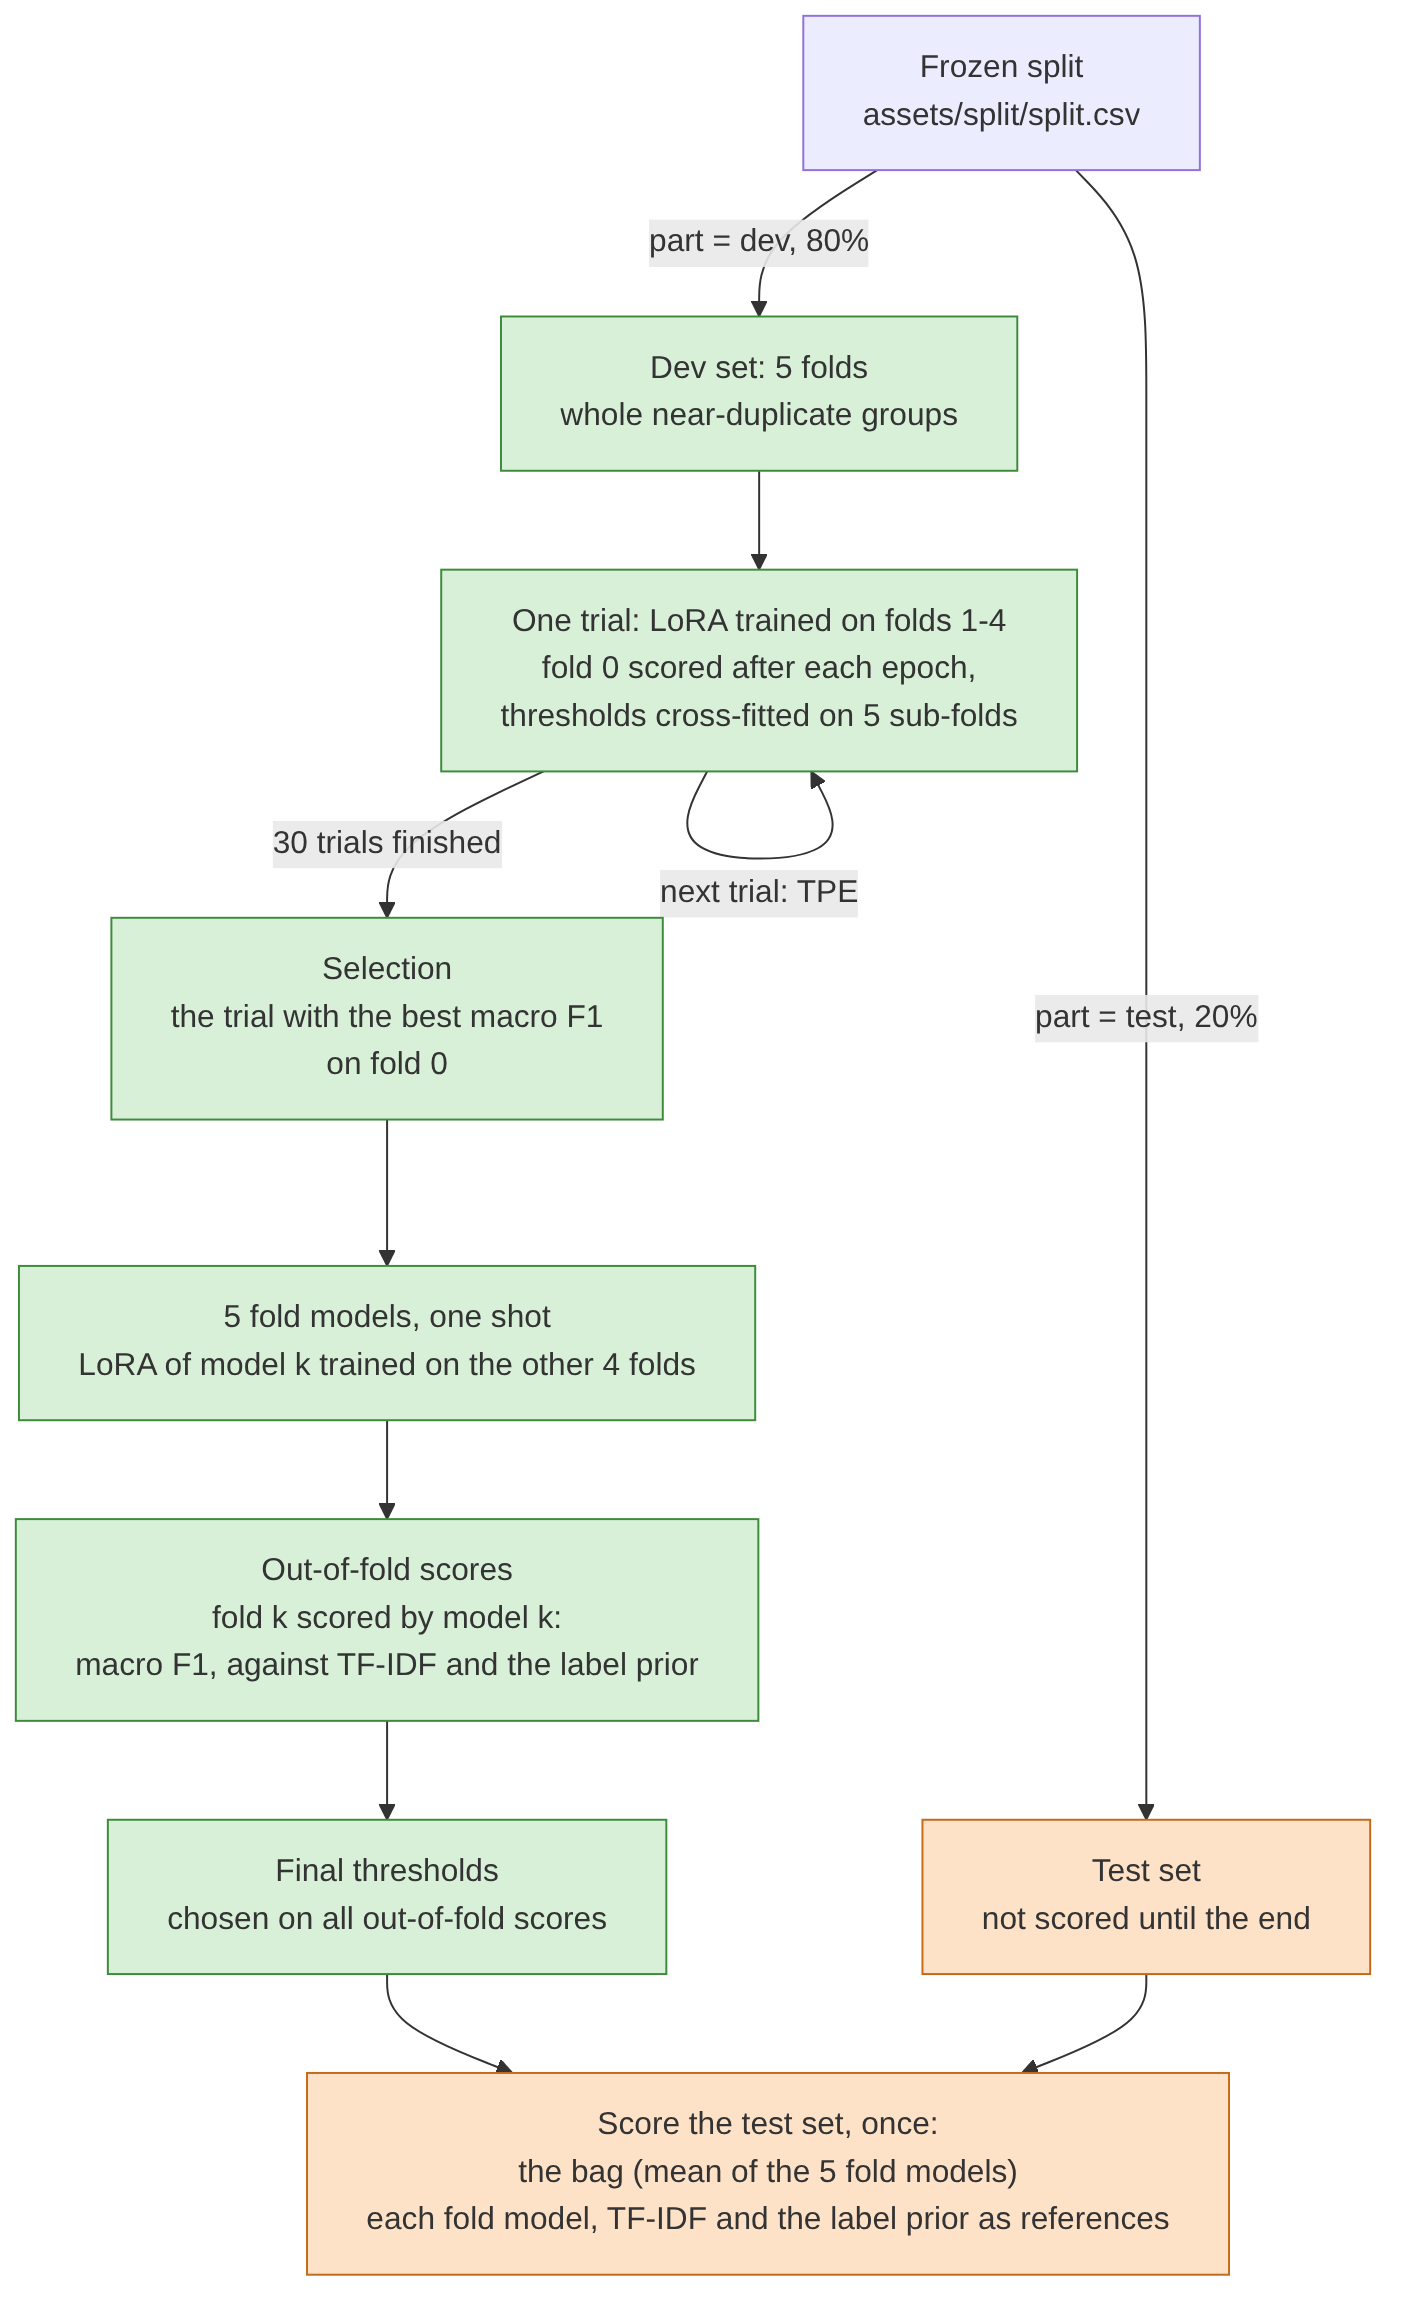

In [1]:
from IPython.display import Image

Image(filename="figures/modernbert_protocol.png", width=440)

## 1. Setup

The method's code and settings live in the package `codeforces_tags.methods.modernbert`
(`settings.py` holds `VARIANTS["modernbert_lora"]`), its frozen files in
`assets/methods/modernbert_lora/`. This notebook reads them with the framework's readers. It
imports neither optuna nor mlflow, nor any training code: it imports `modeling.py` for the
tokenizer and the bag's average only. `check_frozen_method` first checks that the frozen files
of the method, of the TF-IDF baseline and of the label prior are complete and agree with the
frozen split, and `check_dataset` that the dataset is the one they were computed on.

In [2]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, without ipywidgets

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from codeforces_tags.analysis.comparison import method_scores
from codeforces_tags.analysis.plotting import (
    plot_confusion_grid,
    plot_intervals,
    plot_latency,
    plot_method_f1,
    plot_study_history,
    plot_tag_confusion,
    setup_style,
)
from codeforces_tags.config import (
    DATASET_SHA256,
    FOCUS_TAGS,
    LATENCY_BUDGET_S,
    LATENCY_PROBLEMS,
    LATENCY_SEED,
    TFIDF_TEST_MACRO_F1,
)
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.evaluation.contamination import load_slice
from codeforces_tags.evaluation.predictions import (
    load_predictions,
    load_run_record,
    load_scores,
)
from codeforces_tags.evaluation.report import ALL_PROBLEMS, compare, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.methods import method_dir, model_dir
from codeforces_tags.methods.modernbert.inputs import encode_problems, pair_budgets
from codeforces_tags.methods.modernbert.modeling import bag_mean, load_tokenizer
from codeforces_tags.methods.modernbert.settings import (
    ANALYSIS_FOLDER,
    BAG_FILE,
    CPU_LATENCY_FOLDER,
    ENCODER_FILE,
    FOLD_TEST_SCORES_FILE,
    HISTORY_FILE,
    IMPORTANCES_FILE,
    LORA,
    PARAMS_FILE,
    PRETRAINED_FILE,
    TRAINED_FILE,
    TRIALS_FILE,
    TUNING_FOLDER,
    VARIANTS,
    settings,
    study_recipe,
)
from codeforces_tags.methods.modernbert.weights import check_pretrained
from codeforces_tags.model.thresholds import (
    apply_thresholds,
    cross_fitted_predictions,
    per_tag_thresholds,
)
from codeforces_tags.provenance import check_dataset
from codeforces_tags.splitting import (
    load_split,
    release_years,
    select_part,
    stratified_group_folds,
)
from codeforces_tags.tuning.results import load_tuning_results

setup_style()

In [4]:
VARIANT = VARIANTS[LORA]  # the method's settings
METHOD_DIR, MODEL_DIR = method_dir(LORA), model_dir(LORA)  # frozen files; method folder
TUNING_DIR = METHOD_DIR / TUNING_FOLDER  # the study's frozen results
ANALYSIS_DIR = METHOD_DIR / ANALYSIS_FOLDER  # fold models' test scores, CPU and first timings
NOTEBOOK_LATENCY_FILE = ANALYSIS_DIR / "notebook_latency.csv"  # the first run's own timings
FLOOR = "label_prior"  # the F1 floor: every focus tag for every problem
TFIDF = "tfidf"  # the TF-IDF baseline: notebook 04's tag model, frozen by `tuning freeze`

split = load_split()
check_dataset()
for name in (LORA, TFIDF, FLOOR):
    check_frozen_method(name, split=split)
record = load_run_record(METHOD_DIR)
assert record.dataset_sha256 == DATASET_SHA256
entries = record.method_entries
packages = record.environment["packages"]
print(
    f"{record.method}: frozen on {record.created_at[:10]} (commit {record.git['commit'][:7]}) "
    f"on {entries['device']}, {entries['dtype']}; torch {packages['torch']}, "
    f"transformers {packages['transformers']}, peft {packages['peft']}"
)

modernbert_lora: frozen on 2026-10-07 (commit 4c50298) on cuda (NVIDIA GeForce RTX 2080 Ti), fp16-autocast; torch 2.14.1, transformers 5.19.0, peft 0.21.2


## 2. The inputs: statement and solution in 1,024 tokens

The model reads one sequence per problem, `[CLS] statement [SEP] solution [SEP]`: the
statement (description, input and output specifications, after `preprocess()`) and the
accepted Python solution, as written. The notes and the sample inputs and outputs are left out
for now (section 8).

The frozen split gives the dev set, with its 5 folds and near-duplicate groups, and the test
set, whose frozen predictions only section 6 reads.

In [5]:
problems = load_dataset()
dev = select_part(problems, split, "dev")
test = select_part(problems, split, "test")
dev_labels, test_labels = focus_labels(dev), focus_labels(test)
folds = dev["fold"]
print(f"dev: {len(dev):,} problems in {folds.nunique()} folds; test: {len(test):,} problems")
dev_labels.groupby(folds).sum().rename_axis("dev fold")

dev: 3,988 problems in 5 folds; test: 994 problems


label,math,graphs,strings,number theory,trees,geometry,games,probabilities
dev fold,,,,,,,,
0,226,87,66,57,53,27,16,15
1,225,88,68,55,53,27,16,15
2,226,87,67,56,52,26,18,15
3,226,86,68,55,51,27,17,15
4,224,86,68,55,52,26,17,14


**How long are the inputs?** The token counts of the statement and the solution, with
ModernBERT's tokenizer, and the share of problems a length limit keeps whole, under the rule of
`pair_budgets` below (the statement first, the solution at least 128 tokens). The tokenizer is
the pinned snapshot's: `check_pretrained` finds the snapshot in the pretrained cache and checks
the sha256 of every file that `model/pretrained.json` pins, the 1.5 GB encoder's included,
before anything reads it.

In [6]:
pretrained = json.loads((MODEL_DIR / PRETRAINED_FILE).read_text(encoding="utf-8"))
snapshot = check_pretrained(pretrained)
tokenizer = load_tokenizer(snapshot)
token_counts = pd.DataFrame(
    {
        column: [
            len(ids)
            for ids in tokenizer(dev[field].tolist(), add_special_tokens=False)["input_ids"]
        ]
        for column, field in (("statement", "statement"), ("solution", "source_code"))
    },
    index=dev.index,
)
pair_tokens = token_counts.sum(axis=1) + 3  # [CLS] and two [SEP]
print(f"{pretrained['repo_id']} at {pretrained['revision'][:7]}; tokens per problem (dev):")
display(
    pd.concat([token_counts, pair_tokens.rename("both")], axis=1)
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round()
)
# The statement stays whole when it fits next to the solution's floor of code_min_tokens tokens.
code_floor = np.minimum(token_counts["solution"], VARIANT.code_min_tokens)
pd.DataFrame(
    {
        "statement whole": [
            (token_counts["statement"] + code_floor + 3 <= n).mean() for n in (512, 1024, 2048)
        ],
        "statement and solution whole": [(pair_tokens <= n).mean() for n in (512, 1024, 2048)],
    },
    index=pd.Index([512, 1024, 2048], name="max tokens"),
).round(3)

answerdotai/ModernBERT-large at 45bb465; tokens per problem (dev):


,statement,solution,both
count,3988.0,3988.0,3988.0
mean,438.0,474.0,914.0
std,170.0,787.0,823.0
min,74.0,12.0,172.0
50%,413.0,279.0,734.0
90%,655.0,987.0,1520.0
99%,937.0,3087.0,3660.0
max,1453.0,19643.0,19927.0


,statement whole,statement and solution whole
max tokens,,
512,0.434,0.214
1024,0.984,0.737
2048,1.000,0.958


**Why 1,024 tokens.** Memory is not the limit: on the 11 GB GPU, LoRA training fits up to the
model's 8,192 tokens with gradient checkpointing (3.4 GiB at batch 1). Time is: a training step
costs about 104 ms per problem at 1,024 tokens, 250 ms at 2,048 and 2.5 s at 8,192
(measured before the first run, fp16, batch 4, 2 and 1). At 1,024 tokens, nearly every
statement and about three problems in four fit whole; doubling the length would keep 96% of
them whole for about 25-30% more time, all of it spent on the tail of long solutions.

**Which part is cut.** When a problem does not fit, the solution is cut first: the statement
says what the problem is about, while a long solution is often a fast-I/O template followed by
the algorithm. The solution still keeps at least 128 tokens. `pair_budgets` shares the budget
and `encode_problems` builds the token ids; both are in `methods/modernbert/inputs.py`, on the
method's prediction path:

In [7]:
dev_ids = encode_problems(dev, tokenizer, VARIANT.max_length, VARIANT.code_min_tokens)
test_ids = encode_problems(test, tokenizer, VARIANT.max_length, VARIANT.code_min_tokens)
print(f"longest input: {max(map(len, dev_ids + test_ids))} tokens")
print(
    f"budgets: {pair_budgets(950, 300, 1024, 128)} for a 950-token statement and a 300-token "
    f"solution, {pair_budgets(400, 2000, 1024, 128)} for 400 and 2,000"
)
example = dev_ids[0]
separator = example.index(tokenizer.sep_token_id)
print(tokenizer.decode(example[:40], clean_up_tokenization_spaces=False), "...")
print(
    "...",
    tokenizer.decode(example[separator - 10 : separator + 30], clean_up_tokenization_spaces=False),
    "...",
)

longest input: 1024 tokens
budgets: (893, 128) for a 950-token statement and a 300-token solution, (400, 621) for 400 and 2,000
[CLS]Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one ...
... b$$$ chosen and erased in each operation.[SEP]
def ii(): return int(input())
def mi(): return map(int, input().split())


if __name__ == ...


## 3. The model and its training

The code is in `methods/modernbert/`: `modeling.py` builds and scores the models, and
`training.py` trains one of them.

**The model** (`classifier_model`, `lora_config`). ModernBERT-large with a classification head
of one output per focus tag. LoRA adds a trainable low-rank update `B A` (rank r, scaled by
alpha / r = 2) next to each linear layer of attention and MLP, while the encoder's own weights
stay frozen. The pooling head (`head`: dense, activation, norm) and the new `classifier` are
trained in full, which brings the trainable share to 1.2%, 2.0% or 3.8% of the weights at rank
8, 16 or 32 (8.3M of 404M at rank 16). Attention runs through PyTorch's SDPA kernels:
FlashAttention 2 needs an Ampere GPU or newer.

**The loss** (`positive_weights`, `WeightedBce`). Binary cross-entropy per tag, with each tag's
positives weighted by `(negatives / positives) ** pos_weight_power`: 0 is plain cross-entropy,
1 balances each tag (a weight of 53 for `probabilities`, 2.5 for `math`), and the study chooses
in between. Rare tags need it most: `probabilities` has about 60 positives in the 3,182 to 3,198
problems of four folds.

**Training** (`training_arguments`, `train_model`). The Hugging Face `Trainer` runs the loop:
- **fp16** mixed precision: the RTX 2080 Ti (Turing) has no bfloat16 tensor cores;
- **gradient accumulation**: 4 problems per forward pass (8.4 GiB at most at 1,024 tokens), and
  4 or 8 passes per optimiser step for the study's batch size of 16 or 32. With a loss function
  of its own, the `Trainer` passes the number of labels of the whole step, so the accumulated
  loss is the step's mean;
- **length-grouped batches** (`group_by_length`): problems of similar length share a batch, so
  little time goes to padding;
- linear warmup, then linear decay to 0, AdamW with weight decay 0.01;
- **no checkpoint on disk** (`save_strategy="no"`): a `Trainer` checkpoint holds pickle files
  (optimizer, RNG state, arguments), which this project never writes, and a trial needs no
  resuming. Only what each fold model trained is saved, as safetensors (section 5).

**Scoring** (`predict_scores`). One function scores problems with one model, during tuning, for
the out-of-fold scores and on the test set: batches of similar length, the same fp16 autocast as
in training on a GPU (float32 on the CPU), and the probability of each tag (the sigmoid of its
logit). The thresholds of `codeforces_tags.model.thresholds` then turn probabilities into tags;
`cross_fitted_predictions` predicts each fold with thresholds chosen on the other folds, as
`cross_fit()` does for the TF-IDF baseline.

The method's settings (`settings(VARIANTS["modernbert_lora"])`), which its run record holds and
its recipe hashes; the search space is in section 4, and the `retrain_*` bounds are those of
`verify --retrain` (section 8):

In [8]:
method_settings = settings(VARIANT)
assert method_settings == entries["settings"], "the package's settings differ from the frozen ones"
pd.Series(
    {key: value for key, value in method_settings.items() if key != "search_space"},
    name=LORA,
).to_frame()

,modernbert_lora
name,modernbert_lora
study_name,modernbert-lora
model_repo,answerdotai/ModernBERT-large
model_revision,45bb4654a4d5aaff24dd11d4781fa46d39bf8c13
lora,True
max_length,1024
lora_targets,"[Wqkv, Wo, Wi]"
trained_modules,"[head, classifier]"
lora_alpha_per_rank,2
weight_decay,0.01


## 4. The tuning study, on one fold

A trial takes about 5 minutes per epoch of training on four folds (`minutes` below), so the
study does not cross-validate each trial: a trial trains on dev folds 1-4 (3,182 problems) and scores fold
0 (806 problems) after each epoch. Section 5 later scores fold 0 out of fold like the other
folds, with a fold model that retrains the chosen configuration on the same problems and seed.
GPU training is not bit-reproducible, so its fold-0 scores are close to the chosen trial's but
not the same; fold 0 is still the fold the configuration was chosen on, so section 5 also
reports the out-of-fold score of folds 1-4 alone, which carries no such selection.

**The objective** (`tuning.held_out_metrics`) is fold 0's macro F1 after the last epoch, with
per-tag thresholds cross-fitted inside fold 0: fold 0 is cut into 5 sub-folds (whole
near-duplicate groups, stratified on the focus tags, with `stratified_group_folds()`), and each
sub-fold is predicted with thresholds chosen on the other four. A threshold chosen on the
problems it is scored on would flatter configurations, and most for the rare tags (about 15
positives of `probabilities` in fold 0). The macro average precision, which needs no threshold,
is recorded beside it.

**The search** has 7 dimensions:

| Parameter | Range | Why |
|---|---|---|
| `learning_rate` | 5e-5 to 1e-3, log scale | LoRA updates start at 0 and usually need a higher rate than full fine-tuning |
| `lora_rank` | 8, 16, 32 | capacity of each update |
| `lora_dropout` | 0 to 0.2 | regularisation of the updates, with about 3,200 training problems |
| `epochs` | 2 to 4 | fixed for a configuration: no early stopping on the scored fold |
| `batch_size` | 16, 32 | problems per optimiser step (4 per pass, 4 or 8 passes) |
| `warmup_ratio` | 0 to 0.2 | share of the steps with a rising learning rate |
| `pos_weight_power` | 0 to 1 | how much the loss favours each tag's positives |

The sampler is TPE (multivariate, seeded), after 10 random trials. **Pruning**
(`tuning.SameEpochsMedianPruner`) stops a trial after an epoch when its macro F1 falls below the
median of the trials trained for as many epochs, at that epoch, once 3 of them exist. Comparing
a trial with every other trial at the same epoch, as Optuna's `MedianPruner` does, would favour
short trials: a 2-epoch trial ends its learning-rate decay at epoch 2, where a 4-epoch trial is
halfway.

The training problems (folds other than 0), the scored fold and its sub-folds, whose
positives per tag show the stratification at work:

In [9]:
in_tuning_fold = (folds == VARIANT.tuning_fold).to_numpy()
subfolds = stratified_group_folds(
    dev_labels[in_tuning_fold], dev.loc[in_tuning_fold, "group"], VARIANT.subfolds, VARIANT.seed
).rename("subfold")
print(f"training problems: {(~in_tuning_fold).sum():,}; scored fold: {in_tuning_fold.sum():,}")
dev_labels[in_tuning_fold].groupby(subfolds).sum()

training problems: 3,182; scored fold: 806


label,math,graphs,strings,number theory,trees,geometry,games,probabilities
subfold,,,,,,,,
0,45,17,13,11,11,5,3,3
1,47,17,13,13,10,5,4,3
2,46,17,13,11,11,6,3,3
3,44,18,14,11,11,5,3,3
4,44,18,13,11,10,6,3,3


**Where the study ran.** The first run of this notebook ran the study, in 5 hours of training
on the RTX 2080 Ti, in an Optuna journal, the gitignored
`experiments/modernbert_lora/optuna.jsonl`. The journal records the settings of the recipe
(model, input length, search space...), and a study refuses to resume under other ones. An
interrupted run resumed where it stopped: a trial left running by a killed process was marked
failed (and kept out of the training time), and the sampler was seeded again with the number of
trials already run, so that the resumed run drew new configurations rather than the first ones
again (a resumed study is therefore not the one an uninterrupted run would have made). A trial
that ran out of GPU memory or diverged (non-finite scores) failed without stopping the study, up
to 5 of them.

The package's `tune` command (`tuning.run_study`) runs the same study from the same journal.
`export` froze its results in `assets/methods/modernbert_lora/tuning/`, reading the journal
without writing to it: the chosen trial and the study's recipe (`params.json`), every trial
(`trials.csv`), each finished trial's scores after each epoch (`history.csv`) and the parameter
importances (`importances.csv`). No command runs the study again: what follows reads these
files.

**The trials.** `value` is the scored fold's macro F1 after the last epoch the trial ran
(`epochs_run`: for a pruned trial, the epoch it was stopped at), `macro_ap` its macro average
precision, `minutes` its training time. The ten best complete trials:

In [10]:
trials = pd.read_csv(TUNING_DIR / TRIALS_FILE)
history = pd.read_csv(TUNING_DIR / HISTORY_FILE)
chosen = json.loads((TUNING_DIR / PARAMS_FILE).read_text(encoding="utf-8"))
assert chosen["recipe"] == study_recipe(VARIANT), "the study ran under another recipe"
print(
    f"{(trials['state'] == 'COMPLETE').sum()} complete, {(trials['state'] == 'PRUNED').sum()} "
    f"pruned, {(trials['state'] == 'FAIL').sum()} failed; "
    f"{trials['minutes'].sum() / 60:.1f} hours of training"
)
trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(10).round(4)

17 complete, 13 pruned, 2 failed; 5.0 hours of training


,number,state,value,epochs_run,macro_ap,minutes,learning_rate,lora_rank,lora_dropout,epochs,batch_size,warmup_ratio,pos_weight_power
1,1,COMPLETE,0.6840,2,0.6782,9.7599,0.0005,32,0.0142,2,32,0.1556,0.8700
21,21,COMPLETE,0.6800,3,0.7201,14.6490,0.0009,32,0.0736,3,32,0.1381,0.5106
29,29,COMPLETE,0.6679,3,0.7219,14.6348,0.0005,32,0.0697,3,32,0.1226,0.2004
13,13,COMPLETE,0.6676,3,0.7132,14.5708,0.0003,32,0.0565,3,32,0.1419,0.3222
2,2,COMPLETE,0.6675,3,0.7092,14.5629,0.0009,8,0.0237,3,32,0.1044,0.4147
20,20,COMPLETE,0.6654,4,0.7055,19.4606,0.0003,32,0.0738,4,32,0.1512,0.6514
12,12,COMPLETE,0.6617,2,0.6775,9.7148,0.0008,32,0.0409,2,32,0.1808,0.7023
24,24,COMPLETE,0.6577,2,0.6725,9.8000,0.0005,32,0.0254,2,32,0.1583,0.9013
22,22,COMPLETE,0.6555,2,0.6787,9.7782,0.0006,32,0.1071,2,32,0.1148,0.6474
10,10,COMPLETE,0.6552,4,0.6952,19.4399,0.0008,32,0.1691,4,16,0.1195,0.2455


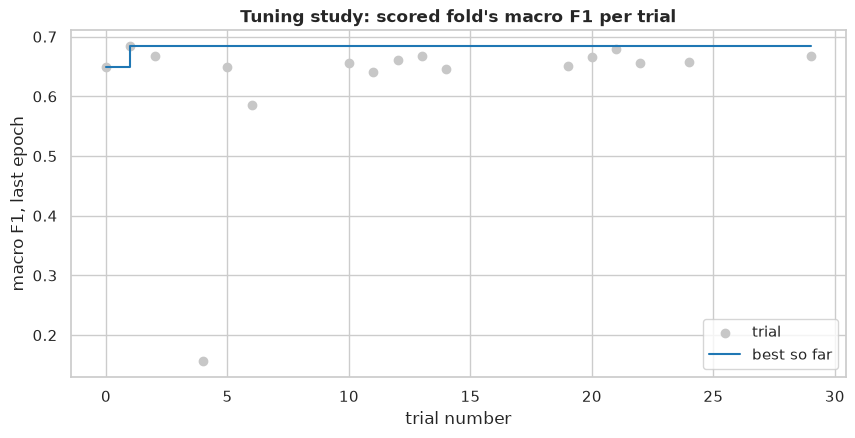

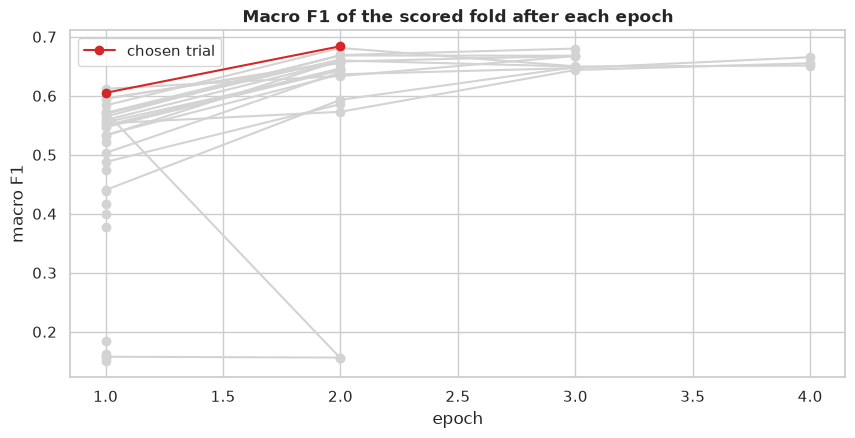

In [11]:
ax = plot_study_history(trials)
ax.set(title="Tuning study: scored fold's macro F1 per trial", ylabel="macro F1, last epoch")
plt.show()
_, ax = plt.subplots()
for number, trial_history in history.groupby("number"):
    is_best = number == chosen["trial"]
    ax.plot(
        trial_history["epoch"],
        trial_history["macro_f1"],
        marker="o",
        color="C3" if is_best else "lightgrey",
        zorder=2 if is_best else 1,
        label="chosen trial" if is_best else None,
    )
ax.set(title="Macro F1 of the scored fold after each epoch", xlabel="epoch", ylabel="macro F1")
ax.legend()
plt.show()

**Which parameters matter.** fANOVA importances (seeded), which `export` computed on the
complete trials: the share of the macro F1's variance across trials that each parameter
explains, alone. With a few dozen trials they are rough, but they say where a larger study
would search:

In [12]:
pd.read_csv(TUNING_DIR / IMPORTANCES_FILE, index_col="parameter").round(3)

,importance
parameter,
lora_rank,0.347
learning_rate,0.243
lora_dropout,0.185
warmup_ratio,0.103
batch_size,0.071
pos_weight_power,0.047
epochs,0.004


In [13]:
assert chosen["params"] == entries["params"] and chosen["trial"] == entries["tuning"]["trial"]
print(f"chosen: trial {chosen['trial']}, scored fold's macro F1 {chosen['tuning_macro_f1']:.4f}")
pd.DataFrame(
    {"search space": pd.Series(VARIANT.search_space), "chosen": pd.Series(chosen["params"])}
)

chosen: trial 1, scored fold's macro F1 0.6840


,search space,chosen
learning_rate,"(5e-05, 0.001)",0.000536
lora_rank,"(8, 16, 32)",32.000000
lora_dropout,"(0.0, 0.2)",0.014207
epochs,"(2, 4)",2.000000
batch_size,"(16, 32)",32.000000
warmup_ratio,"(0.0, 0.2)",0.155631
pos_weight_power,"(0.0, 1.0)",0.870012


The chosen trial's macro F1 is the best of 30 noisy scores on the fold they were all chosen on,
so it overstates what the configuration does on new problems. Section 5's out-of-fold score on
folds 1-4, which the study trained on but never scored, does not have this bias.

**What the study shows**
- **A plateau.** The ten best complete trials score between 0.655 and 0.684, and eight of them
  use rank 32 with batch 32. Two near copies tell how noisy one fold's macro F1 is: trial 24
  (learning rate 5.1e-4, rank 32, batch 32, 2 epochs, warmup 0.16, weight power 0.90) scores
  0.658 against 0.684 for trial 1 (5.4e-4, the same rank, batch, epochs and warmup, 0.87). A
  gap of 0.02 or 0.03 between trials is within that noise, so trial 1's lead says little:
  section 5's out-of-fold scores and section 6's bag are what count.
- **Collapsed trainings.** Six trials (4, 9, 16, 26, 30 and 31) ended with a macro F1 of 0.15
  to 0.18, what tagging every problem with every tag gives, and a macro average precision near
  the tags' base rate: their scores carry no information. They are not confined to a corner of
  the space: learning rates from 3.4e-4 to 9.1e-4, ranks 16 and 32, batches 16 and 32. Trial 26
  even learned in its first epoch (macro F1 0.572, like trial 21's 0.565) before collapsing in
  its second (0.155), while trial 21, a near copy of it (learning rate 9.2e-4 against 9.0e-4),
  went on to 0.680. That points to an unstable training rather than bad settings; the fully
  trained head at the learning rate of the LoRA updates, and the narrow range of fp16, are the
  first suspects (section 8). The pruner stopped five of the six after one or two epochs.
- **Importances.** Rank, learning rate and dropout explain most of the variance across the
  complete trials, and the epoch count almost none. The one complete trial that collapsed
  (trial 4, rank 16, batch 16) weighs heavily in it, so this ranking mostly tells which settings
  separate that failure from the rest.

## 5. Five fold models with the chosen configuration

The chosen configuration trained one fold model per dev fold k, on the four other folds, with
nothing tuned again ("one shot"). The first run of this notebook trained them. `adopt` copied
each one's weights into the trained cache, `experiments/trained/modernbert_lora/`, as
`fold_<k>/weights.safetensors` (what LoRA trained: the updates, the pooling head and the
classifier), after checking the recipe and configuration it was trained under; the method
folder's weight list, `model/trained.json`, pins each file by its bytes and sha256
([ADR 0006](../docs/adr/0006-trained-weight-cache.md)). The weights are not committed: a machine
without them reads the frozen files, as this notebook does. `train` (`folds.train_folds`)
would train new fold models: other weights, so a new method, frozen under a new name.

**Collapsed trainings.** A few trials of the study collapsed (five of the six after one epoch,
trial 26 in its second): their scores carried no information (a macro average precision of
about 0.09, the tags' base rate, and a macro F1 of about 0.15, what predicting every tag for
every problem gives). The study just scores them low, but a fold model that collapsed would
spoil the bag. So `training.train_fold_model` checks each fold model on 800 of its own training
problems: a trained model ranks them far better than the base rate, and one whose macro average
precision stays under 0.3 is trained again with the next seed. The check reads training labels
only, never those of the fold the model scores. The run record keeps, for each fold model, the
seed that trained it, the seeds that collapsed before it, its macro average precision on its
training sample and the minutes of every attempt:

In [14]:
trained = json.loads((MODEL_DIR / TRAINED_FILE).read_text(encoding="utf-8"))
fold_models = (
    pd.DataFrame(entries["fold_models"])
    .T.astype({"seed": int, "train_macro_ap": float, "minutes": float})
    .rename_axis("fold model")
)
fold_models["MiB"] = [trained["folds"][name]["bytes"] / 2**20 for name in fold_models.index]
columns = ["seed", "collapsed_seeds", "train_macro_ap", "minutes", "MiB", "adopted_from"]
fold_models[columns].round(3)

,seed,collapsed_seeds,train_macro_ap,minutes,MiB,adopted_from
fold model,,,,,,
fold_0,0,[],0.798,9.117,58.969,experiments/modernbert_lora/adapters/fold_0
fold_1,1,[0],0.741,18.592,58.969,experiments/modernbert_lora/adapters/fold_1
fold_2,0,[],0.813,9.260,58.969,experiments/modernbert_lora/adapters/fold_2
fold_3,0,[],0.732,9.223,58.969,experiments/modernbert_lora/adapters/fold_3
fold_4,0,[],0.754,9.294,58.969,experiments/modernbert_lora/adapters/fold_4


**One encoder, five adapters.** `modeling.LoraBag` loads the encoder once and adds each fold
model's LoRA updates, head and classifier beside it, as a named PEFT adapter; `set_adapter`
chooses which one runs. Each dev fold is scored by its own fold model through this shared
model. `freeze` and `verify` loaded the bag from the method folder and scored each dev fold
again with its fold model: the largest gap with the out-of-fold scores saved right after
training was 0.00e+00. `verify` also scored the test set again with the bag: a gap of 0.00e+00
with the frozen scores, and no prediction flipped. These checks load the weights on the GPU, so
their output is in the commands' logs, not in this notebook.

From the frozen files alone, the next cell checks that the dev rows of `predictions.csv` are the
out-of-fold scores of `scores.csv` predicted with thresholds cross-fitted across the dev folds,
that the bag's thresholds (`model/bag.json`) are those chosen on every out-of-fold score, and
that the bag holds the five fold models of the chosen configuration:

In [15]:
predictions, scores = load_predictions(METHOD_DIR), load_scores(METHOD_DIR)
bag = json.loads((MODEL_DIR / BAG_FILE).read_text(encoding="utf-8"))
oof_scores = scores.loc["dev"].loc[dev.index].set_axis(dev_labels.columns, axis=1)
oof_predictions = predictions.loc["dev"].loc[dev.index].set_axis(dev_labels.columns, axis=1)
_, recomputed = cross_fitted_predictions(oof_scores, dev_labels, folds)
assert recomputed.equals(oof_predictions)
thresholds = per_tag_thresholds(oof_scores, dev_labels)
assert thresholds.tolist() == bag["thresholds"]
assert bag["params"] == chosen["params"] and bag["folds"] == list(fold_models.index)
print(
    f"dev: the {len(oof_scores):,} out-of-fold scores give the frozen predictions and the "
    "bag's thresholds exactly"
)

dev: the 3,988 out-of-fold scores give the frozen predictions and the bag's thresholds exactly


**Out of fold.** Each fold is predicted with per-tag thresholds chosen on the other four folds'
scores, as for the TF-IDF baseline, and scored with group bootstrap intervals. The baseline's
out-of-fold predictions are those of the frozen method `tfidf` (`assets/methods/tfidf/`),
whose macro F1 is checked against notebook 04's tuning study; the label prior, the F1 floor,
is read from its frozen predictions too (`assets/methods/label_prior/`).
`method_scores` scores the three methods on the same problems with the same resamples, and pairs
each with the TF-IDF baseline:

In [16]:
oof = evaluate(dev_labels, oof_predictions, release_years=release_years(dev), groups=dev["group"])
tfidf_predictions = load_predictions(method_dir(TFIDF))
tfidf_oof = tfidf_predictions.loc["dev"].loc[dev.index, dev_labels.columns]  # the focus tags
tfidf_oof_f1 = evaluate(dev_labels, tfidf_oof).macro_f1
# The frozen method is notebook 04's model, to the last digit.
assert tfidf_oof_f1 == load_tuning_results().out_of_fold.at["macro_f1", "f1"], tfidf_oof_f1
print(f"out-of-fold macro F1: {LORA} {oof.macro_f1:.4f}, TF-IDF {tfidf_oof_f1:.4f}")
oof.summary.round(3)

out-of-fold macro F1: modernbert_lora 0.6611, TF-IDF 0.6629


,problems,macro_f1,micro_f1,no_focus_nothing_predicted,macro_f1_low,macro_f1_high,micro_f1_low,micro_f1_high
slice,,,,,,,,
all problems,3988,0.661,0.628,0.635,0.642,0.680,0.614,0.643
focus-tagged,2143,0.733,0.721,NaN,0.714,0.751,0.708,0.735
up to 2017,1626,0.664,0.602,0.736,0.633,0.691,0.577,0.626
from 2018,2362,0.653,0.641,0.543,0.623,0.678,0.623,0.659


Out of fold: F1 of each method, and modernbert_lora against TF-IDF (paired group bootstrap):


,modernbert_lora,tfidf,label_prior,delta,delta_low,delta_high
metric,,,,,,
macro_f1,0.661,0.663,0.149,-0.002,-0.018,0.014
micro_f1,0.628,0.617,0.158,0.011,-0.002,0.023
math,0.611,0.582,0.441,0.029,0.010,0.050
graphs,0.602,0.603,0.196,-0.001,-0.030,0.031
strings,0.665,0.690,0.156,-0.025,-0.055,0.006
number theory,0.585,0.541,0.130,0.043,-0.008,0.090
trees,0.650,0.719,0.123,-0.069,-0.109,-0.034
geometry,0.683,0.652,0.065,0.032,-0.027,0.094
games,0.750,0.835,0.041,-0.085,-0.154,-0.019


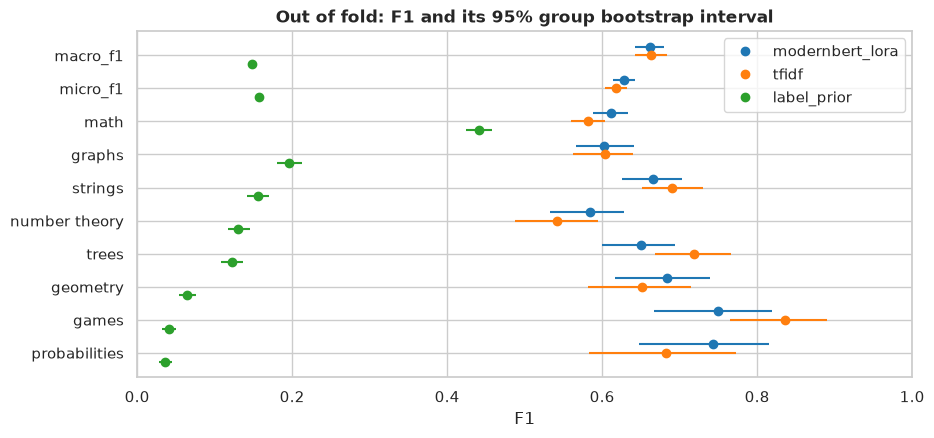

In [17]:
floor_predictions = load_predictions(method_dir(FLOOR))
dev_predictions = {
    LORA: oof_predictions,
    TFIDF: tfidf_oof,
    FLOOR: floor_predictions.loc["dev"].loc[dev.index, dev_labels.columns],
}
dev_scores = method_scores(dev_labels, dev_predictions, dev["group"], baseline=TFIDF)
metric_order = dev_scores.loc[LORA].index
print(f"Out of fold: F1 of each method, and {LORA} against TF-IDF (paired group bootstrap):")
display(
    dev_scores["f1"]
    .unstack("method")
    .loc[metric_order, list(dev_predictions)]
    .join(dev_scores.loc[LORA, ["delta", "delta_low", "delta_high"]])
    .round(3)
)
ax = plot_method_f1(dev_scores)
ax.set(title="Out of fold: F1 and its 95% group bootstrap interval")
plt.show()

,support,tp,fp,fn,precision,recall,f1,f1_low,f1_high
tag,,,,,,,,,
math,1127,776,636,351,0.550,0.689,0.611,0.588,0.634
graphs,434,266,183,168,0.592,0.613,0.602,0.566,0.641
strings,337,253,171,84,0.597,0.751,0.665,0.626,0.703
number theory,278,178,153,100,0.538,0.640,0.585,0.533,0.628
trees,261,164,80,97,0.672,0.628,0.650,0.599,0.693
geometry,133,97,54,36,0.642,0.729,0.683,0.617,0.739
games,84,63,21,21,0.750,0.750,0.750,0.667,0.819
probabilities,74,52,14,22,0.788,0.703,0.743,0.648,0.816


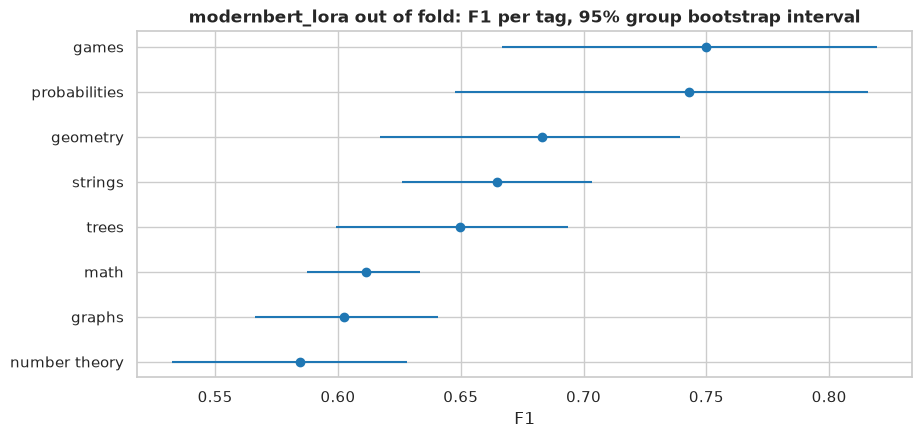

In [18]:
oof_per_tag = oof.per_tag.loc[ALL_PROBLEMS]
display(
    oof_per_tag[
        ["support", "tp", "fp", "fn", "precision", "recall", "f1", "f1_low", "f1_high"]
    ].round(3)
)
ax = plot_intervals(oof_per_tag.sort_values("f1", ascending=False), "f1", "f1_low", "f1_high")
ax.set(title=f"{LORA} out of fold: F1 per tag, 95% group bootstrap interval", xlabel="F1")
plt.show()

**Without the tuning fold.** Fold 0's model retrains the configuration chosen on fold 0 as the
best of 30, so fold 0's out-of-fold score carries the study's selection. Folds 1-4 carry no
such selection (only their thresholds see fold 0's scores): their pooled macro F1, paired with
the TF-IDF baseline on the same problems, is the cleaner dev estimate, and the run record keeps
it (`outside_tuning_fold_macro_f1`). Then fold 0 scored as the study scored it, with its
sub-fold thresholds, and each fold alone:

In [19]:
outside = (folds != VARIANT.tuning_fold).to_numpy()
outside_against_tfidf = compare(
    dev_labels[outside],
    tfidf_oof[outside],
    oof_predictions[outside],
    dev.loc[outside, "group"],
).rename(columns={"baseline": TFIDF, "candidate": LORA})
assert outside_against_tfidf.at["macro_f1", LORA] == entries["outside_tuning_fold_macro_f1"]
print(f"Folds other than {VARIANT.tuning_fold}, {LORA} against TF-IDF (paired group bootstrap):")
display(outside_against_tfidf.round(3))
_, tuning_fold_predictions = cross_fitted_predictions(
    oof_scores[in_tuning_fold], dev_labels[in_tuning_fold], subfolds
)
print(
    f"fold {VARIANT.tuning_fold} with the study's sub-fold thresholds: macro F1 "
    f"{evaluate(dev_labels[in_tuning_fold], tuning_fold_predictions).macro_f1:.3f}, against "
    f"the chosen trial's {chosen['tuning_macro_f1']:.3f}"
)
pd.DataFrame(
    {
        "problems": folds.value_counts().sort_index(),
        "macro_f1": [
            evaluate(dev_labels[folds == fold], oof_predictions[folds == fold]).macro_f1
            for fold in sorted(folds.unique())
        ],
        TFIDF: [
            evaluate(dev_labels[folds == fold], tfidf_oof[folds == fold]).macro_f1
            for fold in sorted(folds.unique())
        ],
    }
).rename_axis("dev fold").round(3)

Folds other than 0, modernbert_lora against TF-IDF (paired group bootstrap):


,tfidf,modernbert_lora,delta,delta_low,delta_high
metric,,,,,
macro_f1,0.663,0.662,-0.000,-0.020,0.019
micro_f1,0.617,0.628,0.011,-0.004,0.025
math,0.586,0.612,0.026,0.003,0.049
graphs,0.588,0.596,0.008,-0.028,0.043
strings,0.684,0.668,-0.016,-0.048,0.017
number theory,0.553,0.590,0.037,-0.020,0.092
trees,0.725,0.652,-0.073,-0.112,-0.032
geometry,0.626,0.661,0.035,-0.035,0.100
games,0.859,0.759,-0.100,-0.184,-0.022


fold 0 with the study's sub-fold thresholds: macro F1 0.659, against the chosen trial's 0.684


,problems,macro_f1,tfidf
dev fold,,,
0,806,0.655,0.665
1,790,0.661,0.661
2,797,0.661,0.652
3,795,0.644,0.656
4,800,0.682,0.681


Both confusion matrices of the out-of-fold predictions, read as in notebook 04:

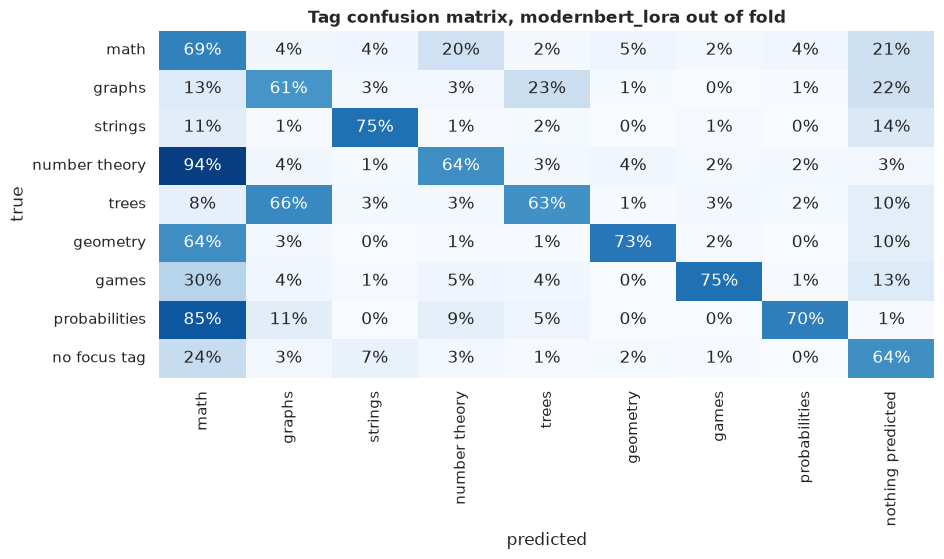

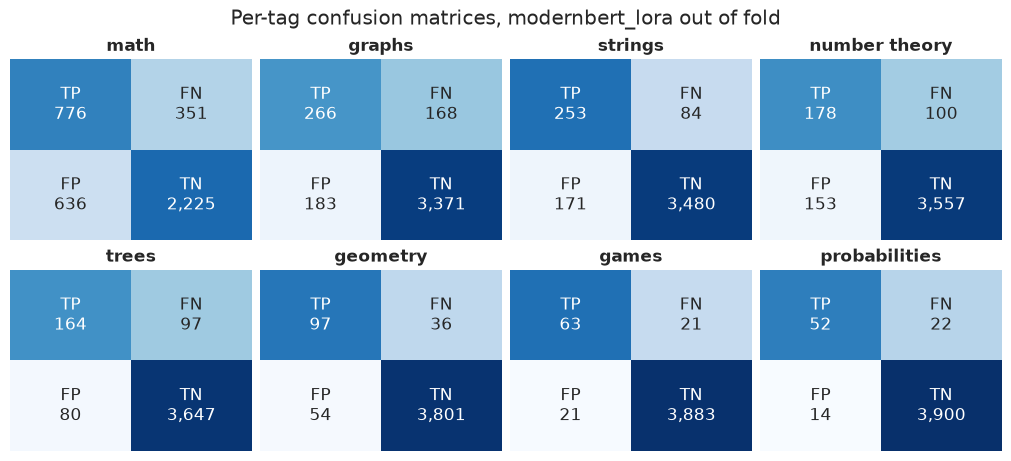

In [20]:
ax = plot_tag_confusion(oof.tag_confusion)
ax.set(title=f"Tag confusion matrix, {LORA} out of fold")
plt.show()
figure = plot_confusion_grid(oof_per_tag)
figure.suptitle(f"Per-tag confusion matrices, {LORA} out of fold")
plt.show()

**Without the self-identifying solutions.** Some solutions name or quote their own problem: a
Codeforces URL, a contest and problem id, or the statement copied into comments. Their problems
form the contamination-sensitivity slice (`assets/slices/self_identifying_solutions.csv`): a
model pretrained on web text and code may have seen these problems' pages, with their tags, and
tag them from the name rather than the content. The out-of-fold macro F1 of each method with and
without them, paired with the TF-IDF baseline as above:

In [21]:
self_identifying = load_slice().index
dev_kept = ~dev.index.isin(self_identifying)
dev_kept_scores = method_scores(
    dev_labels[dev_kept],
    {name: predicted[dev_kept] for name, predicted in dev_predictions.items()},
    dev.loc[dev_kept, "group"],
    baseline=TFIDF,
)
print(f"dev: {(~dev_kept).sum()} self-identifying solutions, {dev_kept.sum():,} problems kept")
pd.concat(
    {
        "all problems": dev_scores.xs("macro_f1", level="metric"),
        "without them": dev_kept_scores.xs("macro_f1", level="metric"),
    },
    axis=1,
).round(3)

dev: 50 self-identifying solutions, 3,938 problems kept


all problems                                             \
                          f1 f1_low f1_high  delta delta_low delta_high   
method                                                                    
modernbert_lora        0.661  0.642   0.680 -0.002    -0.018      0.014   
tfidf                  0.663  0.642   0.683  0.000     0.000      0.000   
label_prior            0.149  0.144   0.153 -0.514    -0.534     -0.494   

                without them                                             
                          f1 f1_low f1_high  delta delta_low delta_high  
method                                                                   
modernbert_lora        0.662  0.642   0.681 -0.001    -0.018      0.017  
tfidf                  0.663  0.642   0.683  0.000     0.000      0.000  
label_prior            0.148  0.144   0.153 -0.515    -0.534     -0.494

**What the out-of-fold scores show**
- **A tie with the TF-IDF baseline on macro F1**: 0.661 [0.642, 0.680] against 0.663, a paired
  difference of -0.002 [-0.018, 0.014]. On folds 1-4 alone, free of the study's selection, the
  difference is the same, 0.000 [-0.020, 0.019]: fold 0 does not flatter the pooled score. Both
  stand far above the floor of the label prior, 0.149, which tags every problem with every tag.
- **Not the same model per tag.** ModernBERT does better on `math` (+0.029 [0.010, 0.050]), and
  probably on `number theory` (+0.043) and `probabilities` (+0.061), whose intervals reach 0;
  it does worse on `trees` (-0.069 [-0.109, -0.034]) and `games` (-0.085 [-0.154, -0.019]).
  A plausible reading: the TF-IDF scores words that name the structure (tree, edges, the
  players of a game), and reads the notes, which ModernBERT does not; ModernBERT reads the
  statement as a whole, which helps the tags described by the reasoning they need rather than
  by their vocabulary. Their errors differ, so combining the two models is the first next step
  (section 8).
- **The study's score was flattered.** Fold 0's out-of-fold macro F1 is 0.655, against the
  chosen trial's 0.684 on the same fold. The fold model retrains that trial's configuration, a
  new draw since GPU training is not bit-reproducible: with the study's own sub-fold thresholds
  it scores 0.659, so most of the gap is the best of 30 falling back, and about 0.004 comes from
  the thresholds, now chosen on folds 1-4.
- **The self-identifying solutions change nothing.** Without the 50 dev problems whose solution
  names its own problem, ModernBERT scores 0.662 [0.642, 0.681] against the TF-IDF baseline's
  0.663, a paired difference of -0.001 [-0.018, 0.017]: neither model owes its score to them.

**The final thresholds** are chosen on all out-of-fold scores (`per_tag_thresholds()`), as the
TF-IDF baseline's are, and saved in the method folder (`model/bag.json`, checked above). They
are probabilities: the bag of section 6 averages the fold models' probabilities and uses the
same thresholds.

In [22]:
thresholds.round(3).to_frame().T

label,math,graphs,strings,number theory,trees,geometry,games,probabilities
threshold,0.496,0.696,0.727,0.775,0.874,0.887,0.934,0.921


## 6. The test set, scored once: with and without bagging

**Fixed before scoring**: the method is the bag, the mean of the 5 fold models' probabilities,
with the thresholds of section 5. Each single fold model, with the same thresholds, the TF-IDF
baseline of notebook 04 and the label prior are scored beside it as references, and nothing is
chosen or changed because of these scores
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). There is no dev estimate of bagging
to compare with: every dev problem was seen by four of the five fold models, so the bag can
only be measured here.

The thresholds were chosen on single fold models' scores: averaging five fold models narrows
the spread of the scores, so the bag's gain over a single fold model includes how well these
thresholds carry over to averaged scores (the share of problems each model tags, below, shows
how far they move, without reading a test label).

The bag's test scores and predictions are the test rows of `scores.csv` and `predictions.csv`,
which `freeze` scored once. It saved each fold model's test scores beside them
(`analysis/fold_test_scores.csv`); the next cell checks that the bag's scores are their mean, as
the bag averages them, and thresholds each fold model's scores with the bag's thresholds, as the
first run did. The test predictions of the TF-IDF baseline and of the label prior are frozen
too: `tuning freeze` scored the test set once with notebook 04's tag model
(`assets/methods/tfidf/`), and the label prior's `freeze` with the floor. The cell also checks
that the TF-IDF baseline's test macro F1 is the one notebook 04 reports (`TFIDF_TEST_MACRO_F1`).

In [23]:
fold_test_scores = pd.read_csv(
    ANALYSIS_DIR / FOLD_TEST_SCORES_FILE,
    index_col=["fold_model", "sample_id"],
    float_precision="round_trip",
)
names = bag["folds"]
test_scores = {
    name: fold_test_scores.loc[name].loc[test.index].set_axis(test_labels.columns, axis=1)
    for name in names
}
test_scores["bag"] = scores.loc["test"].loc[test.index].set_axis(test_labels.columns, axis=1)
bag_scores = bag_mean({name: test_scores[name].to_numpy(np.float32) for name in names})
assert np.array_equal(bag_scores, test_scores["bag"].to_numpy())
test_predictions = {
    name: apply_thresholds(scores_, thresholds) for name, scores_ in test_scores.items()
}
frozen_test = predictions.loc["test"].loc[test.index].set_axis(test_labels.columns, axis=1)
assert test_predictions["bag"].equals(frozen_test)
test_predictions[TFIDF] = tfidf_predictions.loc["test"].loc[test.index, test_labels.columns]
test_predictions[FLOOR] = floor_predictions.loc["test"].loc[test.index, test_labels.columns]
print("Share of problems given each tag (no label read): dev out of fold, then test")
display(
    pd.DataFrame(
        {
            "dev, out of fold": oof_predictions.mean(),
            "test, single fold models": pd.concat(
                [test_predictions[name].mean() for name in names], axis=1
            ).mean(axis=1),
            "test, bag": test_predictions["bag"].mean(),
            f"test, {TFIDF}": test_predictions[TFIDF].mean(),
        }
    ).round(3)
)
test_results = {
    name: evaluate(test_labels, predicted, release_years=release_years(test), groups=test["group"])
    for name, predicted in test_predictions.items()
}
# The frozen tfidf test rows score notebook 04's test macro F1, to the last digit.
assert test_results[TFIDF].macro_f1 == TFIDF_TEST_MACRO_F1, test_results[TFIDF].macro_f1
test_summary = pd.DataFrame(
    {name: result.summary.loc[ALL_PROBLEMS] for name, result in test_results.items()}
).T[["macro_f1", "macro_f1_low", "macro_f1_high", "micro_f1", "micro_f1_low", "micro_f1_high"]]
test_summary.loc["single fold models, mean", ["macro_f1", "micro_f1"]] = test_summary.loc[
    names, ["macro_f1", "micro_f1"]
].mean()
test_summary.round(3)

Share of problems given each tag (no label read): dev out of fold, then test


,"dev, out of fold","test, single fold models","test, bag","test, tfidf"
label,,,,
math,0.354,0.348,0.342,0.426
graphs,0.113,0.127,0.125,0.112
strings,0.106,0.126,0.127,0.110
number theory,0.083,0.089,0.086,0.067
trees,0.061,0.052,0.047,0.051
geometry,0.038,0.031,0.029,0.035
games,0.021,0.020,0.020,0.020
probabilities,0.017,0.021,0.021,0.022


,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high
fold_0,0.693,0.656,0.724,0.646,0.616,0.675
fold_1,0.681,0.643,0.713,0.644,0.616,0.671
fold_2,0.682,0.646,0.714,0.636,0.606,0.664
fold_3,0.694,0.657,0.725,0.646,0.618,0.673
fold_4,0.690,0.653,0.722,0.644,0.617,0.673
bag,0.695,0.658,0.727,0.649,0.621,0.677
tfidf,0.689,0.649,0.721,0.633,0.604,0.661
label_prior,0.149,0.139,0.158,0.158,0.148,0.168
"single fold models, mean",0.688,NaN,NaN,0.643,NaN,NaN


**With and without bagging, paired.** The difference of the bag with each single fold model, on
the same test problems, with paired group bootstrap intervals; then with the TF-IDF baseline and
the label prior:

In [24]:
references = [*names, TFIDF, FLOOR]
bag_against = pd.concat(
    {
        reference: compare(
            test_labels, test_predictions[reference], test_predictions["bag"], test["group"]
        ).loc["macro_f1"]
        for reference in references
    },
    axis=1,
).T.rename(columns={"baseline": "reference", "candidate": "bag"})
print("Test macro F1, the bag against each reference (paired group bootstrap):")
bag_against.round(3)

Test macro F1, the bag against each reference (paired group bootstrap):


,reference,bag,delta,delta_low,delta_high
fold_0,0.693,0.695,0.003,-0.011,0.016
fold_1,0.681,0.695,0.014,0.000,0.029
fold_2,0.682,0.695,0.013,-0.008,0.032
fold_3,0.694,0.695,0.002,-0.015,0.019
fold_4,0.690,0.695,0.005,-0.012,0.024
tfidf,0.689,0.695,0.007,-0.020,0.033
label_prior,0.149,0.695,0.547,0.511,0.577


In [25]:
test_tag_f1 = pd.DataFrame(
    {name: result.per_tag.loc[ALL_PROBLEMS, "f1"] for name, result in test_results.items()}
)
per_tag_view = pd.DataFrame(
    {
        "support": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "support"],
        FLOOR: test_tag_f1[FLOOR],
        TFIDF: test_tag_f1[TFIDF],
        "single, mean": test_tag_f1[names].mean(axis=1),
        "single, min": test_tag_f1[names].min(axis=1),
        "single, max": test_tag_f1[names].max(axis=1),
        "bag": test_tag_f1["bag"],
        "bag, low": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "f1_low"],
        "bag, high": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "f1_high"],
    }
)
print("Test F1 per tag:")
per_tag_view.round(3)

Test F1 per tag:


,support,label_prior,tfidf,"single, mean","single, min","single, max",bag,"bag, low","bag, high"
tag,,,,,,,,,
math,281,0.441,0.619,0.638,0.628,0.643,0.641,0.594,0.685
graphs,108,0.196,0.557,0.570,0.554,0.588,0.586,0.502,0.661
strings,85,0.158,0.660,0.658,0.630,0.673,0.654,0.574,0.725
number theory,72,0.135,0.518,0.602,0.573,0.628,0.611,0.511,0.696
trees,63,0.119,0.772,0.714,0.697,0.732,0.727,0.625,0.813
geometry,33,0.064,0.706,0.637,0.608,0.657,0.645,0.492,0.774
games,21,0.041,0.878,0.860,0.791,0.900,0.878,0.744,0.971
probabilities,18,0.036,0.800,0.825,0.821,0.842,0.821,0.666,0.938


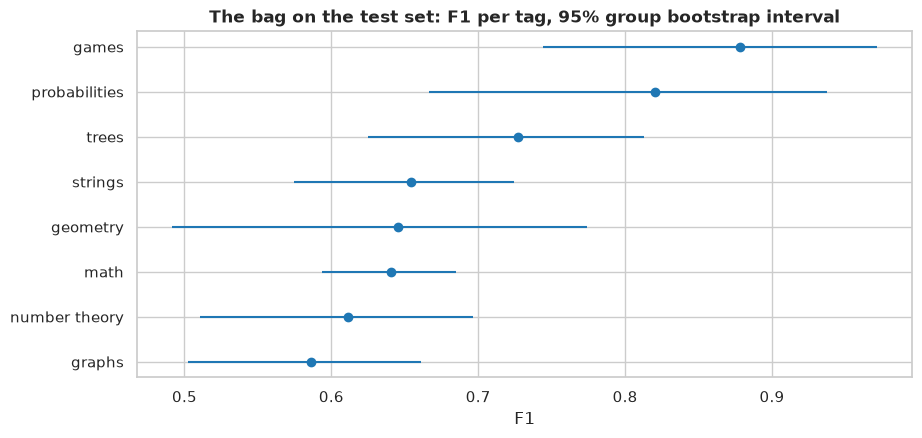

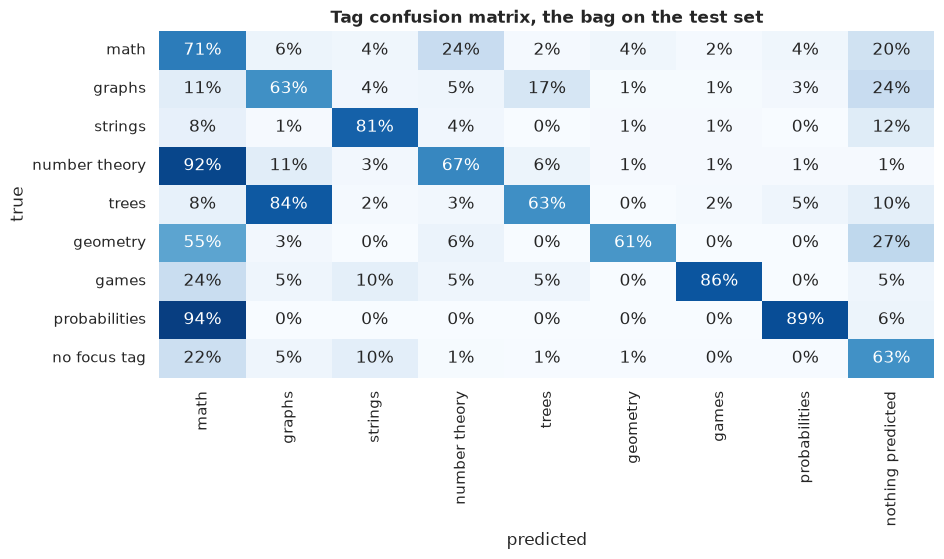

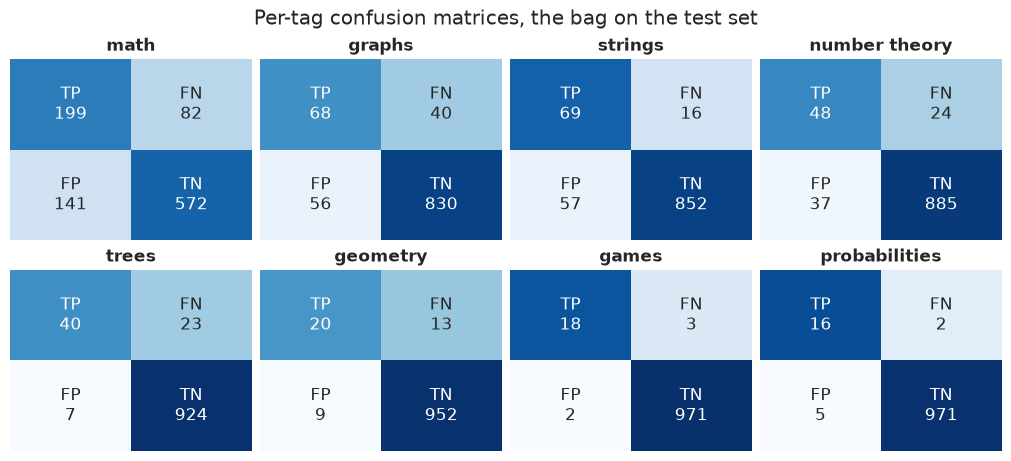

In [26]:
bag_per_tag = test_results["bag"].per_tag.loc[ALL_PROBLEMS]
ax = plot_intervals(bag_per_tag.sort_values("f1", ascending=False), "f1", "f1_low", "f1_high")
ax.set(title="The bag on the test set: F1 per tag, 95% group bootstrap interval", xlabel="F1")
plt.show()
ax = plot_tag_confusion(test_results["bag"].tag_confusion)
ax.set(title="Tag confusion matrix, the bag on the test set")
plt.show()
figure = plot_confusion_grid(bag_per_tag)
figure.suptitle("Per-tag confusion matrices, the bag on the test set")
plt.show()

The F1 of each tag in each slice of the test set, for the bag: all problems against the
focus-tagged ones, and the two release eras.

In [27]:
bag_f1 = test_results["bag"].per_tag["f1"].unstack("slice")
bag_f1.loc[list(FOCUS_TAGS), test_results["bag"].summary.index].round(3)

slice,all problems,focus-tagged,up to 2017,from 2018
tag,,,,
math,0.641,0.765,0.566,0.670
graphs,0.586,0.648,0.604,0.574
strings,0.654,0.831,0.674,0.638
number theory,0.611,0.627,0.490,0.667
trees,0.727,0.748,0.621,0.765
geometry,0.645,0.678,0.625,0.667
games,0.878,0.923,0.769,0.929
probabilities,0.821,0.865,0.833,0.800


**The bag and the references, without the self-identifying solutions.** `method_scores` scores
the method (the bag), the TF-IDF baseline and the label prior on the test set, paired with the
TF-IDF baseline as out of fold, over every test problem and without the self-identifying
solutions:

test: 16 self-identifying solutions, 978 problems kept


all problems                                             \
                          f1 f1_low f1_high  delta delta_low delta_high   
method                                                                    
modernbert_lora        0.695  0.658   0.727  0.007    -0.020      0.033   
tfidf                  0.689  0.649   0.721  0.000     0.000      0.000   
label_prior            0.149  0.139   0.158 -0.540    -0.572     -0.503   

                without them                                             
                          f1 f1_low f1_high  delta delta_low delta_high  
method                                                                   
modernbert_lora        0.695  0.655   0.725  0.006    -0.023      0.034  
tfidf                  0.689  0.648   0.719  0.000     0.000      0.000  
label_prior            0.149  0.139   0.158 -0.540    -0.570     -0.501

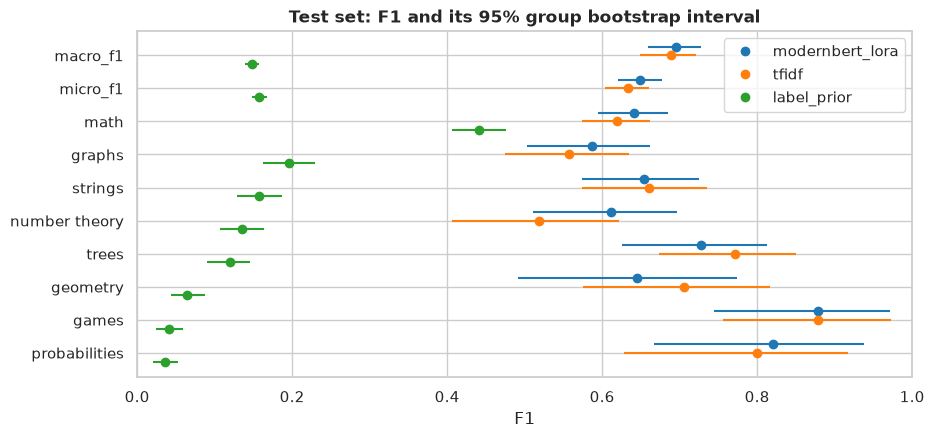

In [28]:
test_methods = {
    LORA: test_predictions["bag"],
    TFIDF: test_predictions[TFIDF],
    FLOOR: test_predictions[FLOOR],
}
test_method_scores = method_scores(test_labels, test_methods, test["group"], baseline=TFIDF)
test_kept = ~test.index.isin(self_identifying)
test_kept_scores = method_scores(
    test_labels[test_kept],
    {name: predicted[test_kept] for name, predicted in test_methods.items()},
    test.loc[test_kept, "group"],
    baseline=TFIDF,
)
print(f"test: {(~test_kept).sum()} self-identifying solutions, {test_kept.sum():,} problems kept")
display(
    pd.concat(
        {
            "all problems": test_method_scores.xs("macro_f1", level="metric"),
            "without them": test_kept_scores.xs("macro_f1", level="metric"),
        },
        axis=1,
    ).round(3)
)
ax = plot_method_f1(test_method_scores)
ax.set(title="Test set: F1 and its 95% group bootstrap interval")
plt.show()

**What the test set shows**
- **The bag scores a macro F1 of 0.695** [0.658, 0.727], and a micro F1 of 0.649.
- **Bagging helps, a little.** The single fold models score 0.681 to 0.694 (0.688 on average),
  and the bag beats each of them, by 0.002 to 0.014; only against the weakest (fold 1's, 0.681)
  does the paired interval stay above 0, and only just ([0.000, 0.029]); against the other four
  it includes 0. Averaging mostly protects from the unlucky fold model: no single one is better
  than the bag, and the gain is largest over the worst. The tagging rates above show that the
  thresholds, chosen on single fold models, carry over to the averaged scores: the bag tags each
  tag about as often as a single fold model does.
- **Against the TF-IDF baseline**: +0.007 [-0.020, 0.033], a tie again. As out of fold, the
  bag is ahead on `number theory` (0.611 against 0.518) and `math`, and behind on `trees`
  (0.727 against 0.772). Unlike out of fold, it is behind on `geometry` (0.645 against 0.706),
  ahead on `graphs` and level on `games` (0.878 each): with 18 to 281 positives per tag, the
  test set's per-tag differences are noisy.
- **Against the label prior**: +0.547 [0.511, 0.577]. The floor scores 0.149, as out of fold.
- **Test against out of fold.** Both models score higher on the test set than out of fold
  (0.695 and 0.689 against 0.661 and 0.663), as notebook 04 found for the TF-IDF baseline: the
  test set happens to be a little easier, within the resampling noise of its 994 problems.
- **Without the 16 self-identifying solutions** of the test set, the bag scores 0.695
  [0.655, 0.725] and the TF-IDF baseline 0.689, a paired difference of +0.006 [-0.023, 0.034]:
  the same tie.

## 7. Latency and memory

PROBLEM.md asks for a single prediction in under ten seconds. The framework's latency harness
(`python -m codeforces_tags.tracking latency`) times the frozen method as the CLI would run it:
`load_method` on the method folder, which checks the sha256 of the encoder and of the five fold
models before it builds the bag, then `predict` on one raw problem at a time, for 50 dev
problems drawn with `LATENCY_SEED`, after one warm-up call, then one call over all 50. The
timed path is the method's own: `raw_to_problems` (the checked `preprocess()`), the token ids,
one forward pass per fold model, the mean of their probabilities and the thresholds. The
harness ran on the RTX 2080 Ti, in fp16 (`latency.csv`, the file the framework's eligibility
rule reads, [ADR 0004](../docs/adr/0004-tagging-method-framework.md)); the method's
`latency-cpu` command ran the same on the CPU, in float32 (`analysis/cpu/latency.csv`).

In [29]:
latencies = {
    "GPU": load_latency(METHOD_DIR),
    "CPU": load_latency(ANALYSIS_DIR / CPU_LATENCY_FOLDER),
}
latency_ids = dev.sample(LATENCY_PROBLEMS, random_state=LATENCY_SEED).index
assert all(set(timed.seconds.index) == set(latency_ids) for timed in latencies.values())
harness = pd.DataFrame(
    {
        device: {
            "problems": len(timed.seconds),
            **latency_summary(timed.seconds),
            "over_budget": (timed.seconds >= LATENCY_BUDGET_S).sum(),
            "one_call_s": timed.bulk_s,
            "load_s": timed.load_s,
        }
        for device, timed in latencies.items()
    }
).T.rename_axis("device")
harness = harness.astype({"problems": int, "over_budget": int})
harness["under_budget"] = harness["max_s"] < LATENCY_BUDGET_S
print(
    f"the bag, timed by the harness; torch's CPU threads on this machine: "
    f"{torch.get_num_threads()} (latency-cpu ran with torch's default)"
)
harness.round(2)

the bag, timed by the harness; torch's CPU threads on this machine: 6 (latency-cpu ran with torch's default)


,problems,median_s,p95_s,max_s,over_budget,one_call_s,load_s,under_budget
device,,,,,,,,
GPU,50,0.33,0.38,0.50,0,8.32,10.34,True
CPU,50,10.91,16.07,19.57,31,700.53,5.61,False


**The first run's own timings.** Before the migration, this notebook timed the same 50 problems
itself, with the same weights on the same GPU, through a prediction function of its own; on the
CPU, the first 10 of them. It timed a single fold model beside the bag. Those timings are kept
in `analysis/notebook_latency.csv`; the last lines compare the two measurements of the bag on
the same problems:

problems  median_s   p95_s   max_s  under_budget
device model                                                           
gpu    one fold model        50     0.064   0.079   0.083          True
       bag                   50     0.288   0.349   0.358          True
cpu    one fold model        10     1.830   2.430   2.604          True
       bag                   10     9.304  12.394  13.223         False

GPU, the bag on the first run's 50 problems: median 0.33 s in the harness against 0.29 s, 1.10 times as long at the median
CPU, the bag on the first run's 10 problems: median 11.55 s in the harness against 9.30 s, 1.25 times as long at the median


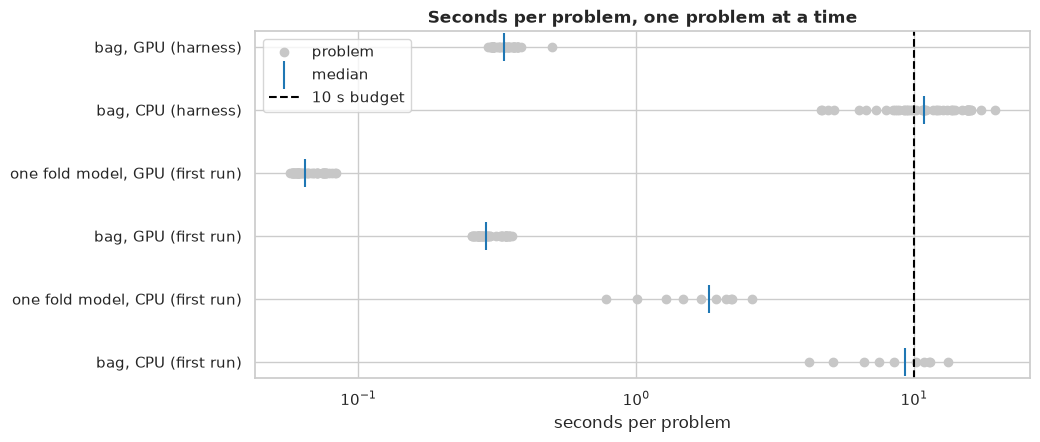

In [30]:
# The file names the models "single adapter" and "bag of 5".
notebook_latency = pd.read_csv(NOTEBOOK_LATENCY_FILE).replace(
    {"model": {"single adapter": "one fold model", "bag of 5": "bag"}}
)
first_run = {
    (device, model): table.set_index("sample_id")["seconds"]
    for (device, model), table in notebook_latency.groupby(["device", "model"], sort=False)
}
first_run_summary = pd.DataFrame(
    {
        key: {"problems": len(seconds), **latency_summary(seconds)}
        for key, seconds in first_run.items()
    }
).T.rename_axis(["device", "model"])
first_run_summary = first_run_summary.astype({"problems": int})
first_run_summary["under_budget"] = first_run_summary["max_s"] < LATENCY_BUDGET_S
display(first_run_summary.round(3))
for device, timed in latencies.items():
    first = first_run[(device.lower(), "bag")]
    ratio = timed.seconds.loc[first.index] / first
    print(
        f"{device}, the bag on the first run's {len(first)} problems: median "
        f"{timed.seconds.loc[first.index].median():.2f} s in the harness against "
        f"{first.median():.2f} s, {ratio.median():.2f} times as long at the median"
    )
ax = plot_latency(
    {
        **{f"bag, {device} (harness)": timed.seconds for device, timed in latencies.items()},
        **{
            f"{model}, {device.upper()} (first run)": seconds
            for (device, model), seconds in first_run.items()
        },
    }
)
ax.set(title="Seconds per problem, one problem at a time")
plt.show()

**Memory.** The encoder's weights against what the five fold models add, from the files: the
pinned snapshot's `model.safetensors` (float32; it holds the pretrained pooling head, which each
fold model replaces with its own trained copy) and each fold model's weights file, whose bytes
`model/trained.json` records (float32: the LoRA updates, the head and the classifier). Loaded,
float32 weights take the same memory as on disk, give or take the files' headers:

In [31]:
encoder_mib = (snapshot / ENCODER_FILE).stat().st_size / 2**20
fold_mib = pd.Series({name: entry["bytes"] for name, entry in trained["folds"].items()}) / 2**20
one_fold_mib, count = fold_mib.mean(), len(fold_mib)
pd.Series(
    {
        "encoder (shared), MiB": encoder_mib,
        "one fold model, MiB": one_fold_mib,
        "trainable share of one model, %": 100 * one_fold_mib / (encoder_mib + one_fold_mib),
        f"{count} fold models on one encoder, MiB": encoder_mib + fold_mib.sum(),
        f"{count} separate full models, MiB": count * encoder_mib + fold_mib.sum(),
    },
    name="float32, from the files",
).round(1).to_frame()

,"float32, from the files"
"encoder (shared), MiB",1510.2
"one fold model, MiB",59.0
"trainable share of one model, %",3.8
"5 fold models on one encoder, MiB",1805.0
"5 separate full models, MiB",7845.8


**What latency and memory show**
- **On the GPU, the bag fits the budget many times over**: the harness measured 0.33 s per
  problem at the median, 0.38 s at the 95th percentile and 0.50 s at most, and 8.3 s for one
  call over the 50 problems. Loading takes 10.3 s, once per process: it checks the sha256 of the
  1.5 GB encoder and of the five fold models before building the bag. The five forward passes
  run one after the other. PEFT can also run the five adapters in one forward pass over five
  copies of the problem (mixed-adapter batches), but needs the head trained through LoRA for it,
  and was measured slower on this GPU during development (0.30 s against 0.23 s per problem at
  900 tokens): one problem of a thousand tokens already keeps the GPU busy.
- **On the CPU, the bag is over the budget.** In float32, on the 6 threads torch uses by
  default, the harness measured 10.9 s per problem at the median, 16.1 s at the 95th percentile
  and up to 19.6 s: 31 of the 50 problems take ten seconds or more. The method meets PROBLEM.md's
  budget on a GPU only. The framework's eligibility rule for the CLI reads the GPU timings
  (`latency.csv`), whose slowest problem takes 0.50 s, so it counts `modernbert_lora` as
  eligible; served on a machine without a GPU, it would break the budget.
- **A single fold model would fit on the CPU.** The first run timed one fold model at 1.8 s per
  problem at the median on the CPU (2.6 s at most, on 10 problems) and 0.06 s on the GPU,
  against 9.3 s (13.2 s at most) and 0.29 s for the bag. A CPU deployment would serve one fold
  model, or first make the model cheaper (section 8). On the same problems, the harness's bag
  took 1.10 times as long as the first run's at the median on the GPU, and 1.25 times on the
  CPU: the two measurements time different code (the framework's `predict`, against the first
  run's own function) in different sessions, and CPU timings move with the machine's load. Both
  agree on what matters: far under the budget on the GPU, over it on the CPU.
- **One encoder for five fold models.** Each fold model adds 59 MiB (rank 32, 3.8% of the
  weights of one model); the five together cost 1.8 GiB with their shared encoder (1,805 MiB),
  against 7.7 GiB for five separate models (7,846 MiB).

## 8. Takeaways and next steps

**Results**
- **Tuning on one fold** (section 4): 30 trials, 5 hours of training on one GPU, a plateau at a
  macro F1 of 0.66-0.68 on fold 0, where two near-identical configurations differ by 0.026: one
  fold is a noisy judge, but it was enough to find a configuration (rank 32, batch 32, 2 epochs,
  learning rate 5.4e-4, positives weighted by the class ratio to the power 0.87). Six trials
  collapsed, and so did one fold model on its first seed: the training is unstable, and the
  collapse check of section 5 is what keeps the bag sound.
- **Out of fold** (section 5): a macro F1 of 0.661 [0.642, 0.680], tied with the TF-IDF baseline
  (paired -0.002 [-0.018, 0.014]) and far above the label prior's 0.149, with different
  strengths: better on `math`, `number theory` and `probabilities`, worse on `trees` and
  `games`. Folds 1-4 alone, which the study never scored, give 0.662.
- **Test set, scored once** (section 6): the bag of five fold models scores 0.695 [0.658, 0.727],
  above each of its single fold models (0.681 to 0.694) and level with the TF-IDF baseline
  (0.689; paired +0.007 [-0.020, 0.033]). Leaving out the self-identifying solutions moves no
  macro F1 by more than 0.002, out of fold or on the test set.
- **Latency** (section 7): under the ten seconds on a GPU (0.33 s for the bag at the median,
  0.50 s at most), over them on a CPU (10.9 s at the median, up to 19.6 s), where a single fold
  model would fit (1.8 s at the median). One encoder serves the five fold models in 1.8 GiB
  instead of 7.7 GiB.
- **A frozen tagging method.** The code moved to the package `codeforces_tags.methods.modernbert`,
  and `modernbert_lora` was frozen in `assets/methods/modernbert_lora/` from the first run's study
  and fold models without changing a score. Its weights stay in a local cache that the method
  folder pins by hash ([ADR 0006](../docs/adr/0006-trained-weight-cache.md)). `verify`
  re-derives the dev predictions and the thresholds from the frozen scores, and scores both parts
  again with the cached fold models. `verify --retrain` trains the five fold models again, each
  from the seed that trained it, and checks them against the frozen ones on bounds the settings
  declared before any retraining (correlation and median gap of the scores, flipped predictions,
  paired difference of the dev macro F1; [ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md)).
  Run twice, it failed two of the four bounds both times. The retrained fold models start bit
  for bit where these did, and their scores agree closely (median gap 0.010 and 0.014, about 2%
  of the predictions flipped). But their bags score 0.634 and 0.642 out of fold, against this
  bag's 0.661, while the two differ from each other by only +0.007 [-0.005, +0.020]. GPU training
  is not reproducible, and its run-to-run spread is as large as the differences between the
  methods: this bag's out-of-fold score sits on the high side of its configuration's, and a
  retrained one would likely score below the TF-IDF baseline.

**Next steps**
- **Measure the training noise before comparing.** Train each fold model three to five times and
  report the bag's out-of-fold macro F1 as a mean with its spread; differences between methods
  smaller than that spread are not differences.
- **Combine ModernBERT and the TF-IDF baseline.** Their per-tag strengths are opposite, so an
  average of their scores, or a per-tag stacking, chosen out of fold, should beat both. ModernBERT's
  out-of-fold and test scores are frozen (`scores.csv`), and so are the TF-IDF baseline's, in
  the method `tfidf`, which makes this cheap: a composite method of the framework (`depends_on`)
  over the two.
- **Stabilise the training**: a lower learning rate for the fully trained head than for the
  LoRA updates (or LoRA on the head too), bfloat16 on an Ampere GPU, and a look at the training
  loss of a collapsing run. Then tune across folds rather than on one, to choose on a less noisy
  score.
- **Read more of the problem**: 2,048 tokens (96% of problems whole instead of 74%), the notes
  (which the TF-IDF baseline reads) and the sample inputs and outputs.
- **A cheaper model for the CPU**: ONNX Runtime with int8 weights, distilling the bag into a
  single fold model, or ModernBERT-base, which notebook 07 fine-tunes in full (half the training
  and inference time; a bag of five took 5.5 s at 900 tokens on this CPU, measured before the
  first run).
- **Learn from every tag**: the 29 other tags as extra outputs of the same model, a cheap source
  of supervision for the shared encoder.
- **Thresholds for the bag**: they are the single fold models' (section 6). Nested cross-fitting
  would give the bag out-of-fold scores of its own, at five times the training cost.
- **Serve it from the CLI.** The CLI's method is chosen on the dev out-of-fold macro F1 alone,
  among the eligible frozen methods ([ADR 0004](../docs/adr/0004-tagging-method-framework.md)):
  `modernbert_lora` is eligible on a GPU, and so is `tfidf`, the TF-IDF baseline, tied with it
  out of fold.